In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

In [13]:
# --- movies ---
movies = pd.read_csv(
    "movies.dat",
    sep="::", engine="python",
    names=["movieId", "title", "genres"],
    encoding="latin-1",
)

# --- ratings ---
ratings = pd.read_csv(
    "ratings.dat",
    sep="::", engine="python",
    names=["userId", "movieId", "rating", "timestamp"],
)
# Utilisateurs

users = pd.read_csv(
    "users.dat",
    sep="	", engine="python",
    encoding="latin-1"
)

In [14]:
users.head()

,Sl.No.,Gender,Age,Occupation,Zip-code,City,State,LocationType,Lat,Long,Location,Decommisioned
0,1,F,1,10,48067,ROYAL OAK,MI,PRIMARY,42.50,-83.15,NA-US-MI-ROYAL OAK,False
1,2,M,56,16,70072,MARRERO,LA,PRIMARY,29.88,-90.11,NA-US-LA-MARRERO,False
2,3,M,25,15,55117,SAINT PAUL,MN,PRIMARY,44.94,-93.10,NA-US-MN-SAINT PAUL,False
3,4,M,45,7,2460,NEWTONVILLE,MA,PRIMARY,42.35,-71.20,NA-US-MA-NEWTONVILLE,False
4,5,M,25,20,55455,MINNEAPOLIS,MN,PRIMARY,44.96,-93.26,NA-US-MN-MINNEAPOLIS,False


In [29]:
movies.isna().mean()

movieId       0.0
title         0.0
genres        0.0
genre_list    0.0
dtype: float64

In [17]:
print(movies.shape)
movies.head()

(3883, 3)


,movieId,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


#### On a un total de 3883 films repertoriés

genre_list
Drama          1603
Comedy         1200
Action          503
Thriller        492
Romance         471
Horror          343
Adventure       283
Sci-Fi          276
Children's      251
Crime           211
War             143
Documentary     127
Musical         114
Mystery         106
Animation       105
Fantasy          68
Western          68
Film-Noir        44
Name: count, dtype: int64


<Axes: ylabel='genre_list'>

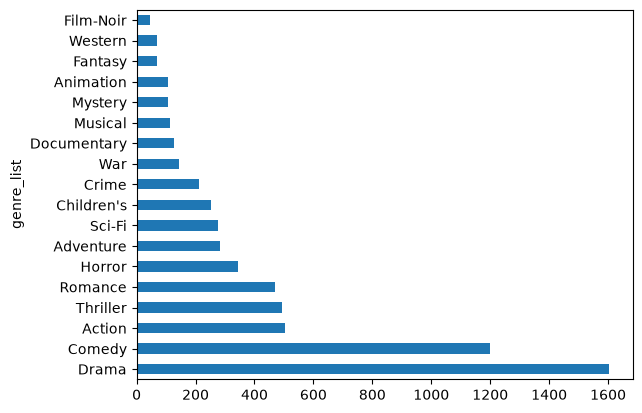

In [19]:
movies["genre_list"] = movies["genres"].str.split("|")
genre_counts = movies.explode("genre_list")["genre_list"].value_counts()

print(genre_counts)
genre_counts.plot(kind="barh")

#### Deux catégories de films sont beaucoup représentés. Les Drama et les comedy

In [20]:
movie_genres = movies[["movieId", "genre_list"]].explode("genre_list")
df = ratings.merge(movie_genres, on="movieId", how="left")

genre_stats = (
    df.groupby("genre_list")["rating"]
      .agg(nb_notes="count", note_moyenne="mean")
      .sort_values("nb_notes", ascending=False)
)
print(genre_stats)

             nb_notes  note_moyenne
genre_list                         
Comedy         356580      3.522099
Drama          354529      3.766332
Action         257457      3.491185
Thriller       189680      3.570466
Sci-Fi         157294      3.466521
Romance        147523      3.607465
Adventure      133953      3.477257
Crime           79541      3.708679
Horror          76386      3.215013
Children's      72186      3.422035
War             68527      3.893327
Animation       43293      3.684868
Musical         41533      3.665519
Mystery         40178      3.668102
Fantasy         36301      3.447371
Western         20683      3.637770
Film-Noir       18261      4.075188
Documentary      7910      3.933123


#### Les notes moyennes ne sont pas très significatives. Elles ne varient que de quelques dixièmes. En plus on a pas le même nombre de votes pour chaque genres. On ne peut pas dire que le genre _Film-noir_ est le plus aimé avec une moyenne de 4.075188 alors qu'il n'y a que 18261 votes. Tandis que d'autres films ont près de 350000 votes. 

In [21]:
comparaison = pd.DataFrame({
    "part_films": genre_counts / genre_counts.sum(),
    "part_notes": genre_stats["nb_notes"] / genre_stats["nb_notes"].sum(),
})
comparaison["ratio"] = comparaison["part_notes"] / comparaison["part_films"]
print(comparaison.sort_values("ratio", ascending=False))

             part_films  part_notes     ratio
genre_list                                   
Sci-Fi         0.043071    0.074837  1.737525
Fantasy        0.010612    0.017271  1.627563
Action         0.078496    0.122493  1.560503
War            0.022316    0.032604  1.461012
Adventure      0.044164    0.063732  1.443092
Film-Noir      0.006866    0.008688  1.265319
Animation      0.016386    0.020598  1.257061
Thriller       0.076779    0.090246  1.175397
Mystery        0.016542    0.019116  1.155608
Crime          0.032928    0.037844  1.149308
Musical        0.017790    0.019761  1.110750
Romance        0.073502    0.070188  0.954920
Western        0.010612    0.009841  0.927326
Comedy         0.187266    0.169653  0.905949
Children's     0.039170    0.034345  0.876814
Horror         0.053527    0.036343  0.678965
Drama          0.250156    0.168678  0.674289
Documentary    0.019819    0.003763  0.189889


Le ratio compare la part des notes reçues par un genre à sa part dans le catalogue.
Il mesure le niveau d'attention que reçoit un genre, pas son appréciation.

- Ratio > 1 : genre sur-noté par rapport à sa présence dans le catalogue (films plus consommés que la moyenne).
- Ratio < 1 : genre sous-noté par rapport à sa présence (films moins consommés, genre de niche).
- Ratio ≈ 1 : attention proportionnelle à la présence dans le catalogue.

L'appréciation d'un genre se lit sur sa note moyenne, à comparer au ratio.
Un ratio élevé indique un biais de popularité au niveau du genre : le modèle aura
plus de données sur ces genres et risque de les recommander davantage.

In [18]:
print(ratings.shape)
ratings.head()

(1000209, 4)


,userId,movieId,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


#### On a plus d'un million d'avis sur les films

In [30]:
ratings.isna().mean()

userId       0.0
movieId      0.0
rating       0.0
timestamp    0.0
dtype: float64

In [22]:
ratings["timestamp"] = pd.to_datetime(ratings["timestamp"],unit="s")
ratings.head(4)

,userId,movieId,rating,timestamp
0,1,1193,5,2000-12-31 22:12:40
1,1,661,3,2000-12-31 22:35:09
2,1,914,3,2000-12-31 22:32:48
3,1,3408,4,2000-12-31 22:04:35


In [23]:
## On peut regrouper par films et caculer des metriques dessus

stat_note = ratings.groupby("movieId")["rating"].agg(
    note_moyenne="mean",
    nb_votes="count").merge(movies[["movieId","title"]], on="movieId")
stat_note.head()


,movieId,note_moyenne,nb_votes,title
0,1,4.146846,2077,Toy Story (1995)
1,2,3.201141,701,Jumanji (1995)
2,3,3.016736,478,Grumpier Old Men (1995)
3,4,2.729412,170,Waiting to Exhale (1995)
4,5,3.006757,296,Father of the Bride Part II (1995)


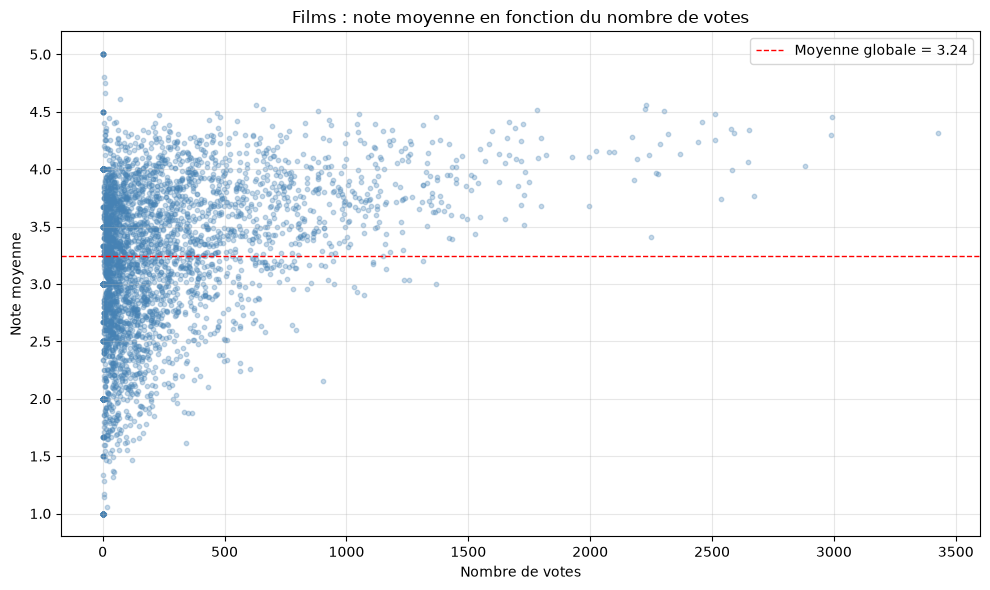

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    stat_note["nb_votes"], stat_note["note_moyenne"],
    alpha=0.3, s=10, color="steelblue",
)

ax.set_xlabel("Nombre de votes")
ax.set_ylabel("Note moyenne")
ax.set_title("Films : note moyenne en fonction du nombre de votes")
ax.grid(alpha=0.3)
ax.axhline(stat_note["note_moyenne"].mean(), color="red", ls="--", lw=1,
           label=f"Moyenne globale = {stat_note['note_moyenne'].mean():.2f}")
ax.legend()

plt.tight_layout()
plt.show()

### Interprétation : note moyenne en fonction du nombre de votes

**Observations**

1. **Forme en entonnoir.** Pour les films avec très peu de votes (moins de 10), la note moyenne varie de 0,5 à 5. Cette dispersion vient de la taille de l'échantillon : avec 1 ou 2 votes, la moyenne reflète l'avis d'une seule personne. Plus le nombre de votes augmente, plus la dispersion diminue et la moyenne se stabilise.

2. **Relation positive entre popularité et note.** Au-delà de 100 votes, presque tous les films ont une note moyenne supérieure à la moyenne globale (3,26), entre 3,5 et 4,3. Les films très notés sont donc aussi ceux qui sont le mieux notés.

3. **Concentration des films à gauche.** La grande majorité des films ont peu de votes (longue traîne) : [X %] des films ont moins de 10 votes.

**Interprétation**

- Les moyennes élevées observées sur les films à 1 ou 2 votes ne sont pas fiables. Un classement par note moyenne brute placerait en tête des films peu connus, sans valeur statistique.
- La relation popularité-note traduit un **biais de sélection** : les utilisateurs notent surtout les films qu'ils ont choisi de voir, et donc qu'ils s'attendent à apprécier. Un modèle apprendra que « populaire » signifie « bien noté », ce qui renforce le biais de popularité.

**Décisions pour l'implémentation**

- Ne pas utiliser la moyenne brute pour classer les films : utiliser une **moyenne régularisée (bayésienne)** qui ramène vers la moyenne globale les films peu notés.
- Définir un **seuil minimal de votes** pour l'évaluation, et traiter les films en dessous comme des cas de **cold start** (repli sur les genres ou les tags).
- **Régulariser** le modèle (factorisation matricielle) pour limiter le surapprentissage sur les films peu notés.
- Évaluer les performances **par tranche de popularité**, pas seulement en global.

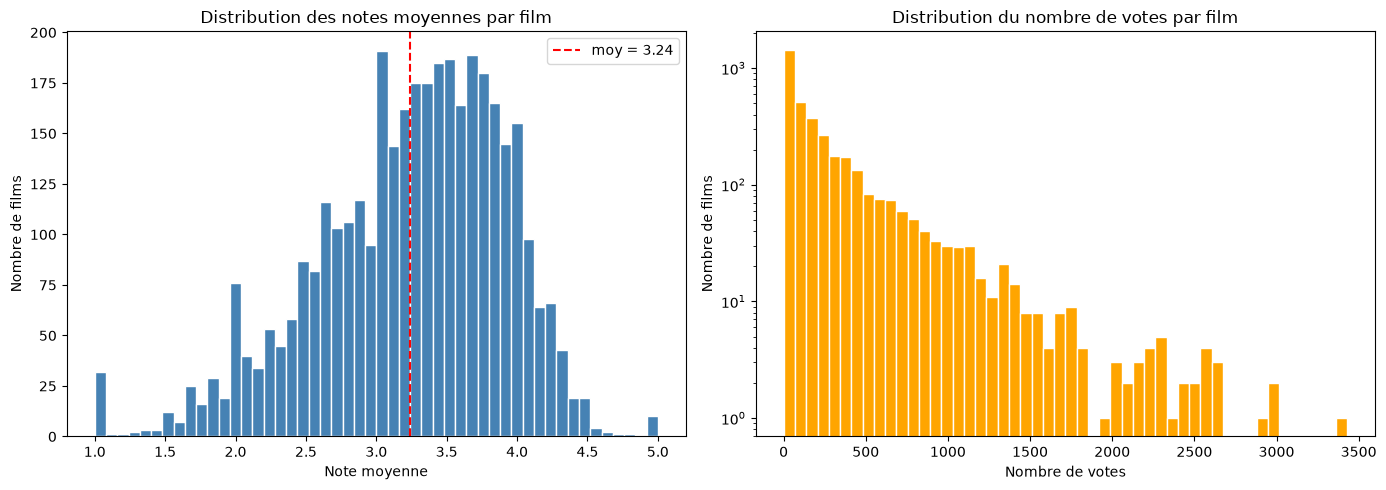

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- distribution des notes moyennes ---
axes[0].hist(stat_note["note_moyenne"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_xlabel("Note moyenne")
axes[0].set_ylabel("Nombre de films")
axes[0].set_title("Distribution des notes moyennes par film")
axes[0].axvline(stat_note["note_moyenne"].mean(), color="red", ls="--",
                label=f"moy = {stat_note['note_moyenne'].mean():.2f}")
axes[0].legend()

# --- distribution du nombre de votes (échelle log car très asymétrique) ---
axes[1].hist(stat_note["nb_votes"], bins=50, color="orange", edgecolor="white")
axes[1].set_xlabel("Nombre de votes")
axes[1].set_ylabel("Nombre de films")
axes[1].set_title("Distribution du nombre de votes par film")
axes[1].set_yscale("log")   # ← indispensable : sinon tout écrasé à gauche

plt.tight_layout()
plt.show()

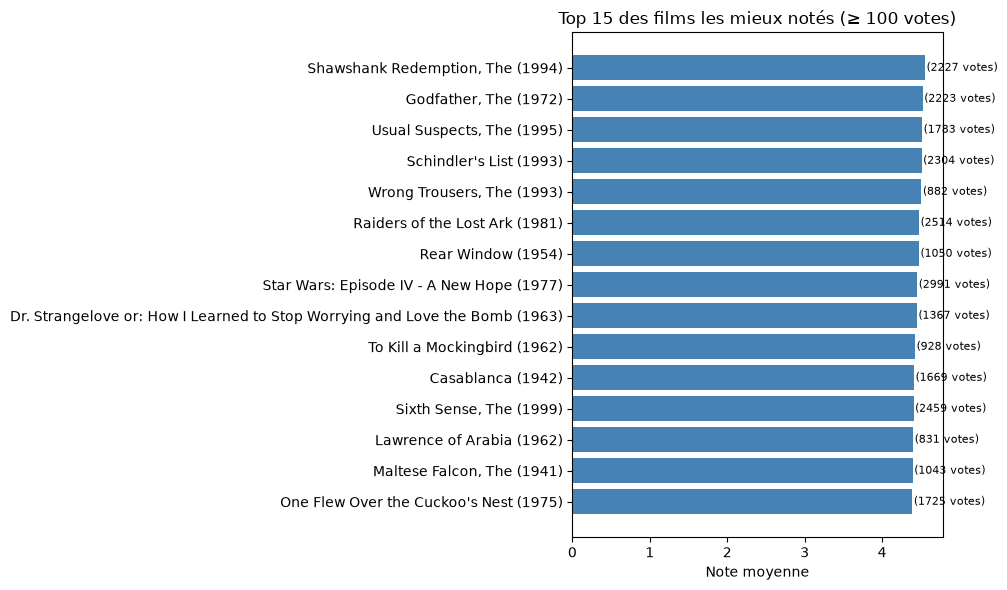

In [28]:
# --- filtre : au moins 100 votes pour être fiable ---
top = (
    stat_note.query("nb_votes >= 700")
         .sort_values("note_moyenne", ascending=False)
         .head(15)
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["title"], top["note_moyenne"], color="steelblue")
ax.invert_yaxis()                       # meilleur en haut
ax.set_xlabel("Note moyenne")
ax.set_title("Top 15 des films les mieux notés (≥ 100 votes)")

# afficher le nb de votes à droite de chaque barre
for i, (note, n) in enumerate(zip(top["note_moyenne"], top["nb_votes"])):
    ax.text(note + 0.02, i, f"({n} votes)", va="center", fontsize=8)

plt.tight_layout()
plt.show()

#### La premiere approche serait de faire une recommandation basée sur l'audience d'un film. C'est a dire on recommande les films qui sont les plus appréciés des utilisateurs. Mais la il faudrait définir une métrique qui prenne en compte, et la note moyenne obtenue par le film, et le nombre de vote obtenu par le film. On utilise une moyenne de note pondérée inspirée de IMDb

$$ WR = \frac{v}{v+m}R+ \frac{m}{v+m}C $$

#### R: Note moyenne du film
#### v: Nombre de notes du film
#### m: Nombre minimal de notes choisi
#### C: Moyenne générale de toutes les notes

In [ ]:
## pour que cette fonction ne fasse pas trop de travail on va juste calculer movies stat et la note moyenne generale une seule fois dans le script 
## et on va utiliser ces valeurs dans notre fonction pour calculer le score

def IMDb(movie_stats,C,k,m):
    ## movie stat est un dataframe qui regroupe par film(groupby) les données suivantes: la moyenne et le nombre de votes
    ## k represente les k_films avec le meilleur score qu'on veut retourner
    ## m agit comme un poids qui rapproche ou eloigne la moy des films a la moy generale
    
    v = movie_stats["rating_count"]
    R = movie_stats["average_rating"]

    scores = (v / (v + m)) * R + (m / (v + m)) * C

    return scores.nlargest(k).index.tolist()


In [24]:
movie_stats = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "count")
).reset_index()

print(movie_stats.head())

   movieId  average_rating  rating_count
0        1        4.146846          2077
1        2        3.201141           701
2        3        3.016736           478
3        4        2.729412           170
4        5        3.006757           296


In [25]:
C = ratings["rating"].mean()

print("Moyenne générale :", C)

Moyenne générale : 3.581564453029317


In [ ]:
## Choix seuil minimal

m = 100

In [26]:
movie_stats["weighted_rating"] = (
    (movie_stats["rating_count"] /
     (movie_stats["rating_count"] + m))
    * movie_stats["average_rating"]
    +
    (m /
     (movie_stats["rating_count"] + m))
    * C
)

In [28]:
recommendations = movie_stats.merge(
    movies[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

recommendations = recommendations.sort_values(
    by="weighted_rating",
    ascending=False
)

print(
    recommendations[
        ["title", "average_rating", "rating_count", "weighted_rating"]
    ].head(20)
)

                                                  title  average_rating  \
309                    Shawshank Redemption, The (1994)        4.554558   
802                               Godfather, The (1972)        4.524966   
513                             Schindler's List (1993)        4.510417   
49                           Usual Suspects, The (1995)        4.517106   
1108                     Raiders of the Lost Ark (1981)        4.477725   
1839  Seven Samurai (The Magnificent Seven) (Shichin...        4.560510   
253           Star Wars: Episode IV - A New Hope (1977)        4.453694   
1066                         Wrong Trousers, The (1993)        4.507937   
843                                  Rear Window (1954)        4.476190   
708                               Close Shave, A (1995)        4.520548   
713   Dr. Strangelove or: How I Learned to Stop Worr...        4.449890   
2557                            Sixth Sense, The (1999)        4.406263   
851                      

In [31]:
def popularity_recommender(ratings, movies,m = 100, n=10):

    C = ratings["rating"].mean()
    

    stats = ratings.groupby("movieId").agg(
        average_rating=("rating", "mean"),
        rating_count=("rating", "count")
    ).reset_index()

    stats["score"] = (
        (stats["rating_count"] / (stats["rating_count"] + m))
        * stats["average_rating"]
        +
        (m / (stats["rating_count"] + m)) * C
    )

    result = stats.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId"
    )

    return result.sort_values(
        "score", ascending=False
    ).head(n)

In [ ]:
top_movies = popularity_recommender(
    ratings,
    movies,
    n=10
)

print(top_movies[["title", "genres", "score"]])

                                                  title  \
309                    Shawshank Redemption, The (1994)   
802                               Godfather, The (1972)   
513                             Schindler's List (1993)   
49                           Usual Suspects, The (1995)   
1108                     Raiders of the Lost Ark (1981)   
1839  Seven Samurai (The Magnificent Seven) (Shichin...   
253           Star Wars: Episode IV - A New Hope (1977)   
1066                         Wrong Trousers, The (1993)   
843                                  Rear Window (1954)   
708                               Close Shave, A (1995)   

                               genres     score  
309                             Drama  4.512744  
802                Action|Crime|Drama  4.484355  
513                         Drama|War  4.471779  
49                     Crime|Thriller  4.467422  
1108                 Action|Adventure  4.443442  
1839                     Action|Drama  4.426039  


In [34]:
top_movies = popularity_recommender(
    ratings,
    movies,
    m=500,
    n=10
)

print(top_movies[["title", "genres", "score"]])

                                          title  \
309            Shawshank Redemption, The (1994)   
802                       Godfather, The (1972)   
513                     Schindler's List (1993)   
1108             Raiders of the Lost Ark (1981)   
253   Star Wars: Episode IV - A New Hope (1977)   
49                   Usual Suspects, The (1995)   
2557                    Sixth Sense, The (1999)   
579            Silence of the Lambs, The (1991)   
2651                     American Beauty (1999)   
851                           Casablanca (1942)   

                               genres     score  
309                             Drama  4.376158  
802                Action|Crime|Drama  4.351738  
513                         Drama|War  4.344787  
1108                 Action|Adventure  4.329058  
253   Action|Adventure|Fantasy|Sci-Fi  4.328783  
49                     Crime|Thriller  4.312213  
2557                         Thriller  4.266908  
579                    Drama|Thriller 

In [35]:
top_movies = popularity_recommender(
    ratings,
    movies,
    m=1500,
    n=10
)

print(top_movies[["title", "genres", "score"]])

                                          title  \
309            Shawshank Redemption, The (1994)   
253   Star Wars: Episode IV - A New Hope (1977)   
802                       Godfather, The (1972)   
513                     Schindler's List (1993)   
1108             Raiders of the Lost Ark (1981)   
2557                    Sixth Sense, The (1999)   
2651                     American Beauty (1999)   
49                   Usual Suspects, The (1995)   
579            Silence of the Lambs, The (1991)   
1848                 Saving Private Ryan (1998)   

                               genres     score  
309                             Drama  4.162959  
253   Action|Adventure|Fantasy|Sci-Fi  4.162402  
802                Action|Crime|Drama  4.144869  
513                         Drama|War  4.144150  
1108                 Action|Adventure  4.142837  
2557                         Thriller  4.093798  
2651                     Comedy|Drama  4.093415  
49                     Crime|Thriller 